In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    '/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv'
)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values using median
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Missing values after cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [4]:
# Define features (X) and target (y)

X = df.drop(columns=['median_house_value', 'ocean_proximity'])
y = df['median_house_value']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20640, 8)
y shape: (20640,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (16512, 8)
X_test shape: (4128, 8)
y_train shape: (16512,)
y_test shape: (4128,)


In [6]:
from sklearn.preprocessing import StandardScaler

# Scale X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Scale y
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

y_test_scaled = scaler_y.transform(
    y_test.values.reshape(-1, 1)
).ravel()

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)
print("y_train_scaled shape:", y_train_scaled.shape)
print("y_test_scaled shape:", y_test_scaled.shape)

X_train_scaled shape: (16512, 8)
X_test_scaled shape: (4128, 8)
y_train_scaled shape: (16512,)
y_test_scaled shape: (4128,)


In [7]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("X_train_poly shape:", X_train_poly.shape)
print("X_test_poly shape:", X_test_poly.shape)

X_train_poly shape: (16512, 45)
X_test_poly shape: (4128, 45)


In [8]:
poly_scaler = StandardScaler()

X_train_poly_scaled = np.column_stack([
    X_train_poly[:, 0],
    poly_scaler.fit_transform(X_train_poly[:, 1:])
])

X_test_poly_scaled = np.column_stack([
    X_test_poly[:, 0],
    poly_scaler.transform(X_test_poly[:, 1:])
])

print("X_train_poly_scaled shape:", X_train_poly_scaled.shape)
print("X_test_poly_scaled shape:", X_test_poly_scaled.shape)

X_train_poly_scaled shape: (16512, 45)
X_test_poly_scaled shape: (4128, 45)


In [9]:
# Adam Optimizer Parameters

learning_rate = 0.001
epochs = 100

beta1 = 0.9
beta2 = 0.999

epsilon = 1e-8

n_features = X_train_poly_scaled.shape[1]

weights = np.zeros(n_features)

m = np.zeros(n_features)
v = np.zeros(n_features)

loss_history = []

print("Adam Optimizer Settings")
print("-----------------------")
print("Number of features:", n_features)
print("Learning rate:", learning_rate)
print("Epochs:", epochs)
print("Beta1:", beta1)
print("Beta2:", beta2)
print("Epsilon:", epsilon)

Adam Optimizer Settings
-----------------------
Number of features: 45
Learning rate: 0.001
Epochs: 100
Beta1: 0.9
Beta2: 0.999
Epsilon: 1e-08


In [10]:
# Adam Optimizer Training

# Initialize parameters
weights = np.zeros(n_features)

m = np.zeros(n_features)
v = np.zeros(n_features)

loss_history = []

n_samples = X_train_poly_scaled.shape[0]
batch_size = 64

t = 0

for epoch in range(epochs):

    # Shuffle training data
    indices = np.random.permutation(n_samples)

    X_shuffled = X_train_poly_scaled[indices]
    y_shuffled = y_train_scaled[indices]

    # Mini-batch training
    for i in range(0, n_samples, batch_size):

        X_batch = X_shuffled[i:i + batch_size]
        y_batch = y_shuffled[i:i + batch_size]

        # Predictions
        predictions = X_batch @ weights

        # Calculate error
        error = predictions - y_batch

        # Calculate gradient
        gradient = (2 / len(y_batch)) * (X_batch.T @ error)

        # Update time step
        t += 1

        # Update first moment (Momentum)
        m = beta1 * m + (1 - beta1) * gradient

        # Update second moment
        v = beta2 * v + (1 - beta2) * (gradient ** 2)

        # Bias correction
        m_corrected = m / (1 - beta1 ** t)
        v_corrected = v / (1 - beta2 ** t)

        # Update weights
        weights -= learning_rate * m_corrected / (
            np.sqrt(v_corrected) + epsilon
        )

    # Calculate training loss
    train_predictions = X_train_poly_scaled @ weights

    train_loss = np.mean(
        (train_predictions - y_train_scaled) ** 2
    )

    loss_history.append(train_loss)

    # Print loss every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}, Loss: {train_loss:.6f}")

print("\nTraining completed!")

Epoch 10, Loss: 0.326353
Epoch 20, Loss: 0.309814
Epoch 30, Loss: 0.305685
Epoch 40, Loss: 0.305059
Epoch 50, Loss: 0.303588
Epoch 60, Loss: 0.307098
Epoch 70, Loss: 0.303666
Epoch 80, Loss: 0.303571
Epoch 90, Loss: 0.302206
Epoch 100, Loss: 0.302070

Training completed!


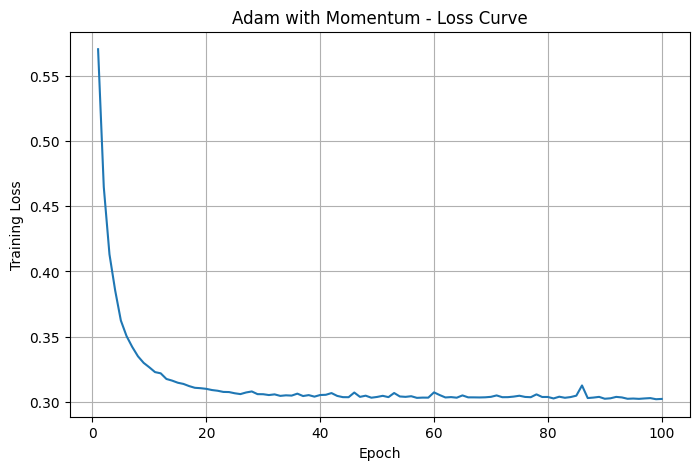

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, epochs + 1), loss_history)

plt.xlabel('Epoch')
plt.ylabel('Training Loss')

plt.title('Adam with Momentum - Loss Curve')

plt.grid(True)
plt.show()

In [12]:
# Make predictions on test data
y_pred_scaled = X_test_poly_scaled @ weights

# Convert predictions back to original scale
y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Convert actual test values back to original scale
y_test_original = scaler_y.inverse_transform(
    y_test_scaled.reshape(-1, 1)
).ravel()

print("Predictions completed!")
print("First 5 Predictions:", y_pred[:5])
print("First 5 Actual Values:", y_test_original[:5])

Predictions completed!
First 5 Predictions: [ 75475.61205177 119860.87845566 261836.40911191 259496.18601542
 283429.91285858]
First 5 Actual Values: [ 47700.  45800. 500001. 218600. 278000.]


In [13]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Calculate evaluation metrics
mse = mean_squared_error(y_test_original, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test_original, y_pred)

r2 = r2_score(y_test_original, y_pred)

# Display results
print("Adam with Momentum - Evaluation Results")
print("---------------------------------------")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"R2 Score: {r2:.4f}")

Adam with Momentum - Evaluation Results
---------------------------------------
MSE:  4371176048.0531
RMSE: 66114.8701
MAE:  46944.2949
R2 Score: 0.6664


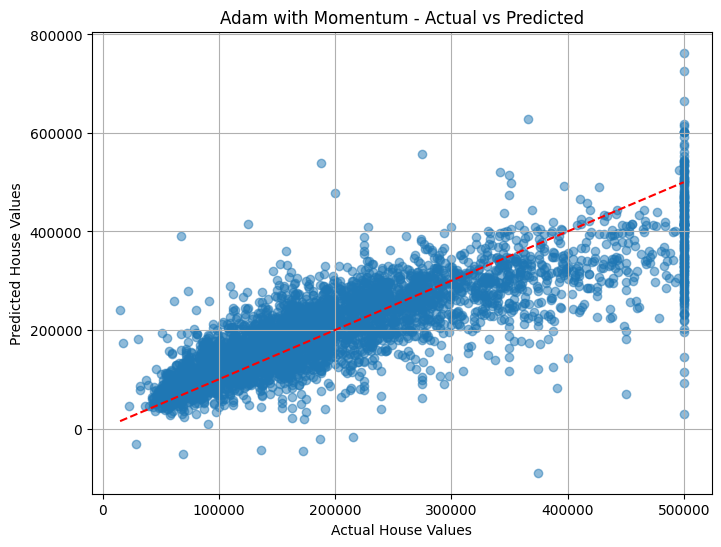

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test_original, y_pred, alpha=0.5)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')

plt.title('Adam with Momentum - Actual vs Predicted')

plt.plot(
    [y_test_original.min(), y_test_original.max()],
    [y_test_original.min(), y_test_original.max()],
    'r--'
)

plt.grid(True)
plt.show()